# Group 5's EDA Notebook


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import warnings

# Suppress warnings.
warnings.filterwarnings("ignore")
pd.options.mode.chained_assignment = None
pd.options.mode.copy_on_write = True

# All generated files go in this runtime's output folder.
output_folder = Path("eda_outputs")
output_folder.mkdir(exist_ok=True)


## Load the data



In [ ]:
filename = "hmda_loan_data.csv"

assert Path(filename).exists(), "Upload the original CSV named hmda_loan_data.csv."
hmda = pd.read_csv(filename, dtype=str, keep_default_na=False)

# Stop here if an incomplete or different CSV was uploaded. sometimes upload would corrupt so i added this check
assert hmda.shape == (40734, 99), "Expected 40,734 rows and 99 columns. Recheck the uploaded CSV."
assert "activity_year" in hmda.columns, "The CSV is missing its original header."
hmda_original = hmda.copy()
hmda.head()


,activity_year,lei,derived_msa-md,state_code,county_code,census_tract,conforming_loan_limit,derived_loan_product_type,derived_dwelling_category,derived_ethnicity,...,denial_reason-2,denial_reason-3,denial_reason-4,tract_population,tract_minority_population_percent,ffiec_msa_md_median_family_income,tract_to_msa_income_percentage,tract_owner_occupied_units,tract_one_to_four_family_homes,tract_median_age_of_housing_units
0,2025,7H6GLXDRUGQFU57RNE97,35614,NY,36079,36079010201,C,FHA:First Lien,Single Family (1-4 Units):Site-Built,Ethnicity Not Available,...,,,,4312,24.93,107700,155,1518,1534,35
1,2025,7H6GLXDRUGQFU57RNE97,35614,NY,36047,36047117400,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Ethnicity Not Available,...,,,,4331,97.62,107700,56,219,1504,0
2,2025,7H6GLXDRUGQFU57RNE97,35614,NY,36081,36081066402,C,VA:First Lien,Single Family (1-4 Units):Site-Built,Ethnicity Not Available,...,,,,3942,96.25,107700,119,730,1017,63
3,2025,7H6GLXDRUGQFU57RNE97,35004,NY,36103,36103147201,C,FHA:First Lien,Single Family (1-4 Units):Site-Built,Ethnicity Not Available,...,,,,3714,42.86,164900,125,820,972,51
4,2025,7H6GLXDRUGQFU57RNE97,15380,NY,36063,36063021200,C,FHA:First Lien,Single Family (1-4 Units):Site-Built,Ethnicity Not Available,...,,,,2310,58.05,101000,72,457,1358,0


In [ ]:
print("Rows:", len(hmda))
print("Columns:", len(hmda.columns))
print("Years:", hmda["activity_year"].unique())
print("States:", hmda["state_code"].unique())
print("Exact duplicate rows:", hmda.duplicated().sum())
hmda["action_taken"].value_counts().sort_index()


Rows: 40734
Columns: 99
Years: ['2025']
States: ['NY']
Exact duplicate rows: 25


,count
action_taken,
1,15793
2,365
3,6070
4,4076
5,3599
6,10831


## Select the records we want
The three actions that we retain are action 1 (originated), action 2 (approved, but not accepted) and action 3 (denied). Purchased loan decisions made elsewhere are thus excluded, as well as both the withdrawal of and/or an applicant's failure to complete their application process do not produce either an approval or denial in this system for those applicants.

Additionally, we retain all home purchase transactions with at least one first-lien, a primary residence and a single-family residential dwelling consisting of one-to-four units. As such, business-loan and open end credit are excluded from our data. Therefore, while retaining a smaller and more comparable sample than would be possible otherwise, our results will only reflect decision-making on a subset of loan applications.


In [ ]:
# Reset first so rerunning this cell gives the same counts.
hmda = hmda_original.copy()
filters = [
    ("action_taken", ["1", "2", "3"]),
    ("loan_purpose", ["1"]),
    ("lien_status", ["1"]),
    ("occupancy_type", ["1"]),
    ("derived_dwelling_category", ["Single Family (1-4 Units):Site-Built"]),
    ("business_or_commercial_purpose", ["2"]),
    ("open-end_line_of_credit", ["2"]),
]

for column, values in filters:
    hmda = hmda.loc[hmda[column].isin(values)].copy()



## Prepare the variables
I retain all of the fields that we will be using and then convert any numeric fields to appropriate numeric types. Blank, NA (Not Available) and exempted values are treated as missing in each of the relevant fields. I also retain missing demographic information and unusual income information from the sample.

Denial is coded as a 1 for Action 3 and a 0 for Actions 1 and/or 2. Denial as measured here indicates what decision was made on the applicant's submitted application, however it does not indicate why an applicant was denied nor can it demonstrate discriminatory behavior.


In [ ]:
numeric_columns = ["income", "loan_amount", "tract_minority_population_percent",
                   "tract_to_msa_income_percentage", "tract_population"]
keep_columns = ["activity_year", "state_code", "lei", "action_taken",
                "derived_race", "derived_ethnicity", "applicant_age",
                "loan_type", "debt_to_income_ratio", "derived_msa-md",
                "county_code", "census_tract"] + numeric_columns
hmda = hmda[keep_columns].copy()

for column in numeric_columns:
    hmda[column] = hmda[column].replace({"": np.nan, "NA": np.nan,
                                       "Exempt": np.nan})
    hmda[column] = pd.to_numeric(hmda[column])

hmda["denied"] = (hmda["action_taken"] == "3").astype(int)
hmda["age_band"] = hmda["applicant_age"].replace({"8888": "Missing"})


DTI combines ranges with discrete values. The range of 36 through 49 is a single band that preserves the original value in the column. Bands are created for missing values (DTI & Age) as well as five tract minority share bands. Tract Composition refers to the neighborhood characteristics of the property. It does not refer to the identity of the applicant.

In [ ]:
hmda["dti_band"] = hmda["debt_to_income_ratio"].replace(
    {"": "Missing", "NA": "Missing", "Exempt": "Missing"}
)
exact_dti = [str(value) for value in range(36, 50)]
hmda.loc[hmda["debt_to_income_ratio"].isin(exact_dti), "dti_band"] = "36%-49%"

# Use nonoverlapping intervals
tract_labels = ["0–<20%", "20–<40%", "40–<60%", "60–<80%", "80–100%"]
hmda["tract_minority_band"] = pd.cut(
    hmda["tract_minority_population_percent"],
    bins=[0, 20, 40, 60, 80, np.inf], labels=tract_labels, right=False
).astype("string").fillna("Missing")

hmda.to_csv(output_folder / "hmda_2025_ny_cleaned.csv", index=False)
hmda.head()


,activity_year,state_code,lei,action_taken,derived_race,derived_ethnicity,applicant_age,loan_type,debt_to_income_ratio,derived_msa-md,...,census_tract,income,loan_amount,tract_minority_population_percent,tract_to_msa_income_percentage,tract_population,denied,age_band,dti_band,tract_minority_band
111,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Not Hispanic or Latino,35-44,1,30%-<36%,28740,...,36111952100,247.0,585000,52.21,68,3687,0,35-44,30%-<36%,40–<60%
112,2025,NY,7H6GLXDRUGQFU57RNE97,1,Joint,Not Hispanic or Latino,35-44,1,30%-<36%,35614,...,36081026902,100.0,305000,95.74,61,4244,0,35-44,30%-<36%,80–100%
113,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Not Hispanic or Latino,25-34,1,30%-<36%,35614,...,36119014701,125.0,225000,42.27,122,4977,0,25-34,30%-<36%,40–<60%
114,2025,NY,7H6GLXDRUGQFU57RNE97,1,White,Ethnicity Not Available,35-44,1,39,35614,...,36081092800,245.0,605000,9.14,181,3204,0,35-44,36%-49%,0–<20%
115,2025,NY,7H6GLXDRUGQFU57RNE97,2,White,Hispanic or Latino,35-44,1,30%-<36%,35614,...,36081071304,100.0,85000,46.01,125,6386,0,35-44,30%-<36%,40–<60%


**Income** is in thousands of dollars, so 173 means $173,000. There are 395 missing incomes and 74 nonpositive values.


In [ ]:
print("Applications:", len(hmda))
print("Denied:", hmda["denied"].sum())
print("Missing income:", hmda["income"].isna().sum())
print("Nonpositive income:", (hmda["income"] <= 0).sum())
print("Missing DTI:", (hmda["dti_band"] == "Missing").sum())
hmda["income"].describe()


Applications: 10513
Denied: 1476
Missing income: 395
Nonpositive income: 74
Missing DTI: 23


,income
count,10118.000000
mean,290.685709
std,483.276447
min,-719.000000
25%,106.000000
50%,173.000000
75%,317.000000
max,16328.000000


## Income distribution
A log scale is used here because many of the largest incomes were too big to be shown with a linear scale, making it difficult to see what the smaller incomes look like. This trick may have been discussed in CMPU250, but if not it's a method learned from CMPU366 - NLP. Only the 10,044 positive reported incomes are included for this plot. The 469 missing or non-positive values are still retained as part of the cleaned data.

Alt Text: Logarithmic histogram of annual income (in thousands), only including positive values. Black bars outline blue bars and add black diagonal hatching to allow bar identification in grayscale.

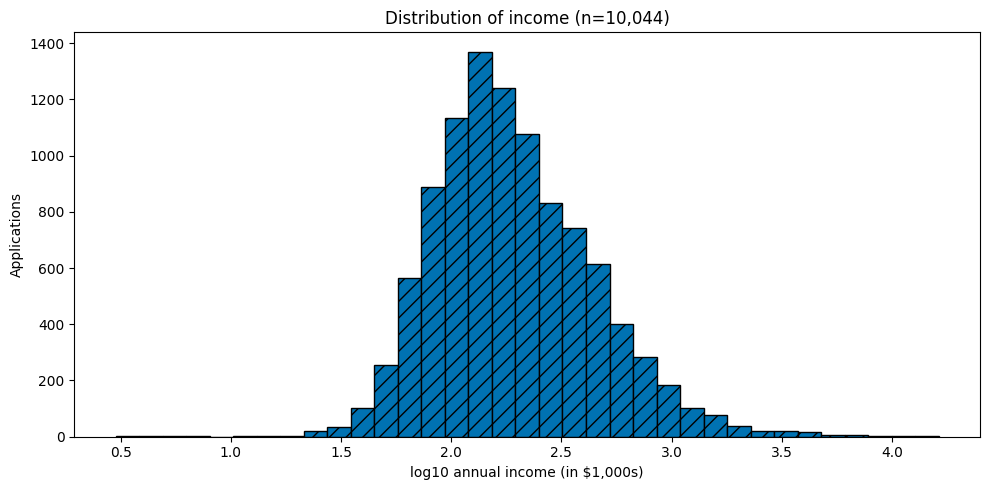

In [ ]:
positive_income = hmda.loc[hmda["income"] > 0, "income"]
log_income = np.log10(positive_income)

ax = log_income.plot.hist(bins=35, figsize=(10, 5), color="#0072B2",
                          edgecolor="black", hatch="//")
ax.set_title(f"Distribution of income (n={len(positive_income):,})")
ax.set_xlabel("log10 annual income (in $1,000s)")
ax.set_ylabel("Applications")
plt.tight_layout()
plt.savefig(output_folder / "income_distribution.png", dpi=200,
            bbox_inches="tight")
plt.show()


The reported incomes have a long right tail: the median is roughly $173,000.

The mean is roughly $291,000.

# Creating DTI Categorical Bands

In creating the DTI Categorical bands, I noticed that HMDA reports debt-to-income ratio in a mixed format though ranges for ranges for most values

(e.g. "20%-<30%"). However, it does exact integers from 36 to 49. I used the pre-built `dti_band` column, which puts
36 to 49 into a single band, and set it as an ordered categorical from lowest to highest DTI.
Limitation with this is that since 36-49 is the largest group i miss to see the distribution across each integer there in comparison to the other bands.
The applications with missing DTI are excluded.

In [ ]:
#Creating the DTI Bands
dti_order = ["<20%", "20%-<30%", "30%-<36%", "36%-49%", "50%-60%", ">60%"]
hmda["dti_band"] = pd.Categorical(
    hmda["dti_band"].where(hmda["dti_band"].isin(dti_order)),
    categories=dti_order,
    ordered=True,
)

# Cleaning the derived_race column

I excluded "Race Not Available" and "Free Form Text Only" because they don't identify a group.
I also dropped groups with fewer than 100 applications (American Indian or Alaska Native, n=28; Native Hawaiian or Other Pacific Islander, n=25; 2 or more minority races, n=21), because percentages based on so few applications are too unstable to interpret.

This leaves four groups: White, Asian, Black or African American, and Joint. Leaving out the smaller groups is a limitation of this analysis, not evidence that they experience no disparities.

In [ ]:
# Filtering out rows with missing race or DTI band. Excluding the "Race Not Available" and "Free Form Text Only" categories.
exclude = ["Race Not Available", "Free Form Text Only"]
plot_df = hmda[hmda["dti_band"].notna() & ~hmda["derived_race"].isin(exclude)]
counts = plot_df["derived_race"].value_counts()
plot_df = plot_df[plot_df["derived_race"].isin(counts[counts >= 100].index)]

### Debt-to-income distribution by applicant race stacked bar chart

This 100% stacked bar chart shows what share of each group's applications falls in each DTI band.
The percentages are calculated within each race, so we can compare groups of different sizes more directly.
A scatter plot wasn't suitable because both variables are categorical.

This chart shows how applicant finances differ by group. This is important because DTI is a major consideration when making lending decisions. It could explain part of any difference in denial rates.

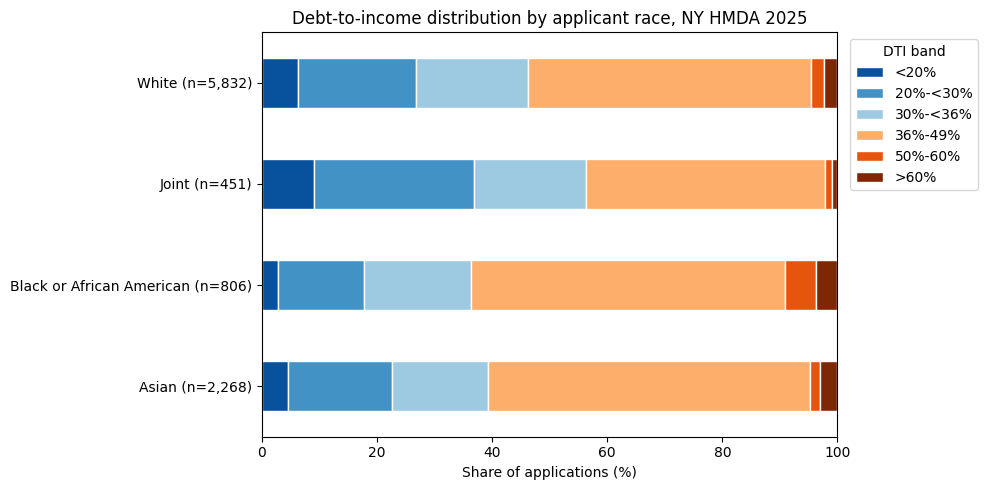

In [ ]:
# Filtering out rows with missing race or DTI band. Excluding the "Race Not Available" and "Free Form Text Only" categories.
exclude = ["Race Not Available", "Free Form Text Only"]
plot_df = hmda[hmda["dti_band"].notna() & ~hmda["derived_race"].isin(exclude)]
counts = plot_df["derived_race"].value_counts()
plot_df = plot_df[plot_df["derived_race"].isin(counts[counts >= 100].index)]

# Chart 1: DTI distribution by race
tab = pd.crosstab(plot_df["derived_race"], plot_df["dti_band"], normalize="index") * 100
n = plot_df["derived_race"].value_counts()
tab.index = [f"{r} (n={n[r]:,})" for r in tab.index]

# Plotting the stacked bar chart with a an accessible colour palette
dti_colors = ["#08519c", "#4292c6", "#9ecae1", "#fdae6b", "#e6550d", "#7f2704"]

ax = tab.plot(kind="barh", stacked=True, figsize=(10, 5),
              color=dti_colors, edgecolor="white", linewidth=1)
ax.set_xlabel("Share of applications (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.set_title("Debt-to-income distribution by applicant race, NY HMDA 2025")
ax.legend(title="DTI band", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig("dti_by_race.png", dpi=200)

def show_with_alt(alt, dpi=150):
    buf = io.BytesIO()
    plt.savefig(buf, format="png", dpi=dpi, bbox_inches="tight")
    plt.close()
    img64 = base64.b64encode(buf.getvalue()).decode()

    show_with_alt(
    "Stacked bar chart of debt-to-income (DTI) ratio bands for New York 2025 HMDA "
    "mortgage applications by applicant race. Black applicants have the largest share "
    "of high DTI applications, with about 9% above 50% DTI versus roughly 2% to 5% for "
    "other groups. Joint applicants have the most low DTI applications, with about 56% "
    "under 36%."
)

    display(HTML(f'<img src="data:image/png;base64,{img64}" alt="{alt}" style="max-width:100%">'))

**Chart description:**

Horizontal 100% stacked bar chart titled "Debt-to-income distribution by applicant race, NY HMDA 2025." Each bar shows the share of applications in six DTI bands: under 20%, 20% to under 30%, 30% to under 36%, 36% to 49%, 50% to 60%, and over 60%. Colors run from dark green (low DTI) to dark red (high DTI).

Approximate (not exact) values:

- White (n=5,832): 6%, 21%, 19%, 49%, 2%, 2%. About 46% under 36% DTI.
- Joint (n=451): 9%, 28%, 19%, 42%, 1%, 1%. About 56% under 36% DTI.
- Black or African American (n=806): 3%, 15%, 18%, 55%, 5%, 4%. About 36% under 36% DTI.
- Asian (n=2,268): 4%, 18%, 17%, 56%, 2%, 3%. About 40% under 36% DTI.

For every group, the 36% to 49% band is the largest.

# Denial rate by tract minority share using a bar plot

I used seaborn’s barplot, which estimates a 95% confidence interval by (drawing out repeated samples with replacement from original data). It did the resampling of the data 1,000 times; taking the 2.5th and 97.5th percentiles of the resampled denial rates.


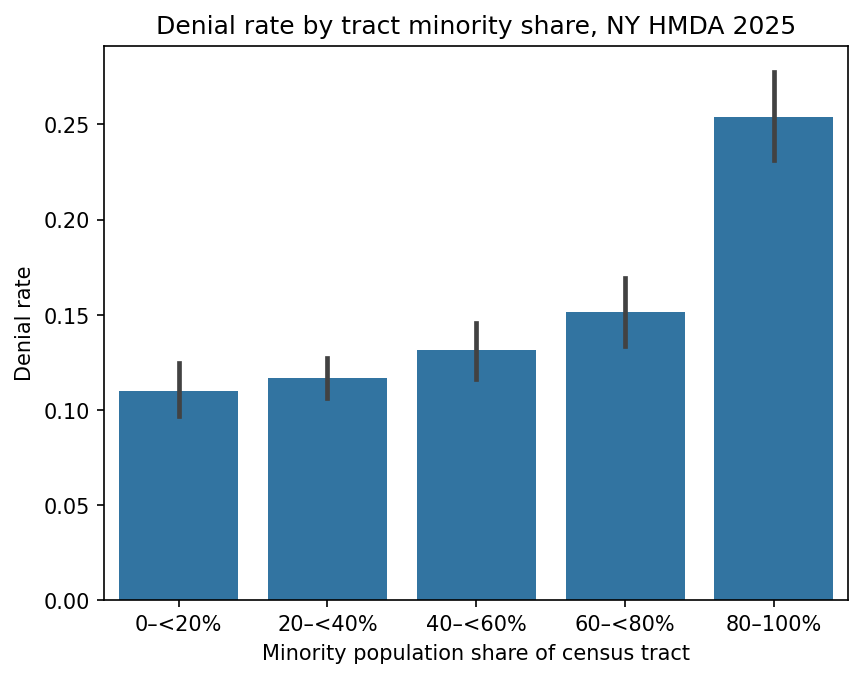

In [ ]:
import seaborn as sns

order = ["0–<20%", "20–<40%", "40–<60%", "60–<80%", "80–100%"]
ax = sns.barplot(data=hmda, x="tract_minority_band", y="denied",order=order, errorbar=("ci", 95))
ax.set_xlabel("Minority population share of census tract")
ax.set_ylabel("Denial rate")
ax.set_title("Denial rate by tract minority share, NY HMDA 2025")

import base64, io
from IPython.display import HTML, display

buf = io.BytesIO()
plt.savefig(buf, format="png", dpi=150, bbox_inches="tight")
plt.close()
img64 = base64.b64encode(buf.getvalue()).decode()

alt = ("Bar chart of mortgage denial rates by the minority population share of the "
       "applicant's census tract, NY HMDA 2025. Denial rates rise gradually from about "
       "11% in tracts under 20% minority to about 15% in tracts 60% to 80% minority, "
       "then jump to about 25% in tracts 80% to 100% minority.")

display(HTML(f'<img src="data:image/png;base64,{img64}" alt="{alt}" style="max-width:100%">'))

**Chart description:** Bar chart titled "Denial rate by tract minority share, NY HMDA 2025." The x-axis shows five bands of census tract minority population share; the y-axis shows denial rate. Error bars show 95% confidence intervals. Approximate values:

- 0% to under 20%: about 11%
- 20% to under 40%: about 12%
- 40% to under 60%: about 13%
- 60% to under 80%: about 15%
- 80% to 100%: about 25%

The increase is modest across the first four bands, with overlapping error bars between neighbors. The 80% to 100% band stands apart, with a rate more than double the lowest band and no overlap with any other band.

## Save the results
This cell is for saving the results. change the bool to True to save/download to your computer a zip.

In [ ]:
import shutil
from pathlib import Path

save_results = True

if save_results:
    archive = shutil.make_archive("eda_results", "zip", output_folder)
    try:
        from google.colab import files   # only available in Colab
        files.download(archive)
    except ImportError:
        print(f"Saved to: {Path(archive).resolve()}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>